In [1]:
DATA = "../data/mtcars.csv"
OUTPUT = "../submission"
ESTIMATOR = f"{OUTPUT}/estimator.pkl"

In [2]:
# Carga de datos


def load_data():

    import pandas as pd

    dataset = pd.read_csv(DATA)
    y = dataset.pop("mpg")
    x = dataset.copy()

    return x, y


x, y = load_data()
x

,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,8,360.0,175,3.15,3.440,17.02,0,0,3,2
5,6,225.0,105,2.76,3.460,20.22,1,0,3,1
6,8,360.0,245,3.21,3.570,15.84,0,0,3,4
7,4,146.7,62,3.69,3.190,20.00,1,0,4,2
8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
9,6,167.6,123,3.92,3.440,18.30,1,0,4,4


In [3]:
# Calidad de datos:

print("Tamaño del dataset:", x.shape)
print("Datos faltantes:", x.isnull().sum().sum())
x.dtypes

Tamaño del dataset: (32, 10)
Datos faltantes: 0


cyl       int64
disp    float64
hp        int64
drat    float64
wt      float64
qsec    float64
vs        int64
am        int64
gear      int64
carb      int64
dtype: object

In [4]:
# Correlación entre variables


def plot_correlation():

    import matplotlib.pyplot as plt
    import pandas as pd
    import seaborn as sns

    dataset = pd.read_csv(DATA)
    corr = dataset.corr()

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        corr,
        cmap="BuPu",
        vmin=-1,
        vmax=1,
        annot=True,
    )
    plt.title("Mapa de calor de correlaciones (mtcars)")
    plt.show()


plot_correlation()

<Figure size 1000x600 with 2 Axes>

In [5]:
# Particionamiento de datos


def make_train_test_split(x, y):

    from sklearn.model_selection import train_test_split

    (x_train, x_test, y_train, y_test) = train_test_split(
        x,
        y,
        test_size=0.20,
        random_state=42,
    )
    return x_train, x_test, y_train, y_test

In [6]:
# Construcción del pipeline


def make_pipeline(alpha=1.0):

    from sklearn.linear_model import Lasso
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    pipeline = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("lasso", Lasso(alpha=alpha, max_iter=10000)),
        ],
        verbose=False,
    )

    return pipeline

In [7]:
# Cálculo de métricas de evaluación


def eval_metrics(y_train_true, y_test_true, y_train_pred, y_test_pred):

    from sklearn.metrics import mean_squared_error, r2_score

    mse_train = mean_squared_error(y_train_true, y_train_pred)
    mse_test = mean_squared_error(y_test_true, y_test_pred)
    r2_train = r2_score(y_train_true, y_train_pred)
    r2_test = r2_score(y_test_true, y_test_pred)

    return mse_train, mse_test, r2_train, r2_test

In [8]:
# Reporte de métricas de evaluación


def report(estimator, mse_train, mse_test, r2_train, r2_test):

    print(estimator, ":", sep="")
    print("-" * 80)
    print(f"  MSE: {mse_test:0.4f} ({mse_train:0.4f})")
    print(f"   R2: {r2_test:0.4f} ({r2_train:0.4f})")

In [9]:
# Modelo base (alpha=1.0)


def train_base_estimator():

    x, y = load_data()
    x_train, x_test, y_train, y_test = make_train_test_split(x, y)

    estimator = make_pipeline(alpha=1.0)
    estimator.fit(x_train, y_train)

    mse_train, mse_test, r2_train, r2_test = eval_metrics(
        y_train,
        y_test,
        estimator.predict(x_train),
        estimator.predict(x_test),
    )
    report(estimator, mse_train, mse_test, r2_train, r2_test)

    return estimator


base_estimator = train_base_estimator()

Pipeline(steps=[('scaler', StandardScaler()), ('lasso', Lasso(max_iter=10000))]):
--------------------------------------------------------------------------------
  MSE: 9.2648 (6.2803)
   R2: 0.7683 (0.8143)


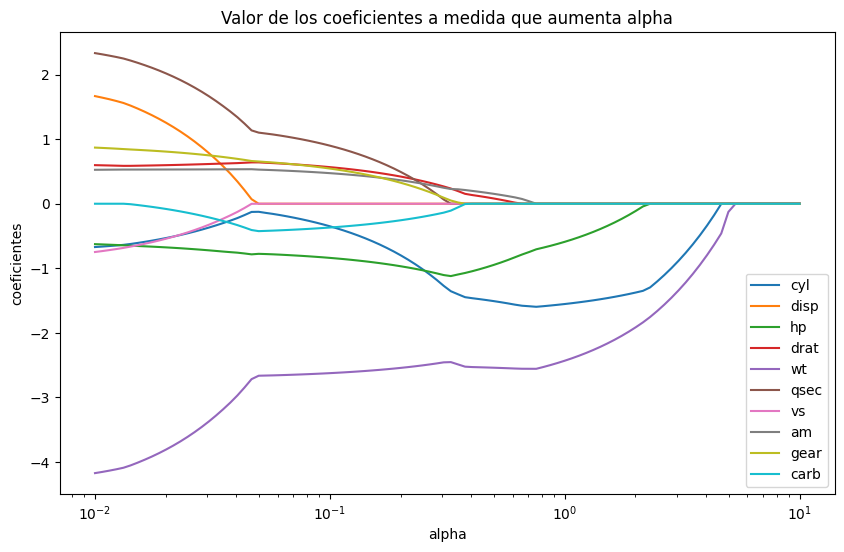

In [10]:
# Análisis del alpha:
#
#   - a medida que alpha crece, Lasso lleva a cero los coeficientes;
#   - las últimas variables en anularse son las más importantes.


def plot_coefficients_path():

    import matplotlib.pyplot as plt
    import numpy as np

    x, y = load_data()
    x_train, _, y_train, _ = make_train_test_split(x, y)

    alphas = np.logspace(-2, 1, 100)
    coefs = []

    for alpha in alphas:
        estimator = make_pipeline(alpha=alpha)
        estimator.fit(x_train, y_train)
        coefs.append(estimator.named_steps["lasso"].coef_)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(alphas, coefs)
    ax.set_xscale("log")
    ax.legend(x.columns)
    ax.set_xlabel("alpha")
    ax.set_ylabel("coeficientes")
    ax.set_title("Valor de los coeficientes a medida que aumenta alpha")
    plt.show()


plot_coefficients_path()

In [11]:
# Búsqueda de hiperparámetros


def make_grid_search(estimator, param_grid, cv=10):

    from sklearn.model_selection import GridSearchCV

    grid_search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        cv=cv,
        scoring="neg_mean_squared_error",
    )

    return grid_search

In [12]:
# Almacenamiento del modelo


def save_estimator(estimator):

    import os
    import pickle

    if not os.path.exists(OUTPUT):
        os.makedirs(OUTPUT)

    with open(ESTIMATOR, "wb") as file:
        pickle.dump(estimator, file)

In [ ]:
# Carga del modelo


def load_estimator():

    import os
    import pickle

    if not os.path.exists(ESTIMATOR):
        return None

    with open(ESTIMATOR, "rb") as file:
        estimator = pickle.load(file)

    return estimator

In [13]:
# Entrenamiento


def train_estimator():

    import numpy as np

    x, y = load_data()
    x_train, _, y_train, _ = make_train_test_split(x, y)

    estimator = make_grid_search(
        estimator=make_pipeline(),
        param_grid={
            "lasso__alpha": np.linspace(0.01, 2.0, 100),
        },
        cv=10,
    )

    estimator.fit(x_train, y_train)

    save_estimator(estimator)


train_estimator()

In [18]:
# Chequeo


def check_estimator():

    x, y = load_data()
    x_train, x_test, y_train, y_test = make_train_test_split(x, y)

    estimator = load_estimator()

    mse_train, mse_test, r2_train, r2_test = eval_metrics(
        y_train,
        y_test,
        estimator.predict(x_train),
        estimator.predict(x_test),
    )

    print("Mejor alpha:", estimator.best_params_)
    print("Mejor score (CV):", estimator.best_score_)
    report(estimator.best_estimator_, mse_train, mse_test, r2_train, r2_test)

    check_estimator()

In [ ]:
# Variables seleccionadas por Lasso (coeficientes distintos de cero)


def selected_features():

    import pandas as pd

    x, _ = load_data()
    estimator = load_estimator()

    coefs = pd.Series(
        estimator.best_estimator_.named_steps["lasso"].coef_,
        index=x.columns,
        name="coef",
    )

    return coefs[coefs != 0].sort_values(key=abs, ascending=False).to_frame()


    selected_features()

NameError: name 'load_estimator' is not defined